# CFS 30-Day Mean Sea Level Pressure

In this example, we will:

1) Use WxData to download 30 days of CFS Mean Sea Level Pressure.
2) Calculate the 30-Day Mean for Mean Sea Level Pressure.
3) Make a polar stereographic plot

## Imports

In [1]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import numpy as np


from wxdata import(
    cfs_pressure,
    cyclic_point
)
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from scipy import signal as signal
from datetime import timedelta

### `cfs_pressure()` Client

```python

def cfs_pressure(western_bound=-180, 
            eastern_bound=180, 
            northern_bound=90, 
            southern_bound=-90, 
            final_forecast_hour=720,
            proxies=None, 
            clear_recycle_bin=False,
            clear_data=False,
            chunk_size=8192,
            notifications='off',
            path=f"CFS/PRESSURE",
            process_data=True,
            convert_temperature=True,
            convert_to='celsius',
            source='aws',
            level_type='pressure',
            variable='geopotential height',
            levels=[1000, 
                    925, 
                    850, 
                    700, 
                    500, 
                    300, 
                    250],
            to_netcdf=False,
            netcdf_path=f"CFS PRESSURE/NETCDF",
            netcdf_filename=f"cfs_pressure.nc",
            delete_previous_netcdf_file=True,
            return_values=True):
```

Click [Here](https://edrewitz.github.io/WxData/cfs_pressure) for the full documentation

In [2]:
ds = cfs_pressure(southern_bound=30,
                  variable='mean sea level pressure',
                  level_type='mean sea level')

Data in local directory is current. Skipping Download
CFS Pressure Data Processing...
CFS Pressure Data Processing Complete.


In [3]:
ds

<xarray.Dataset> Size: 11MB
Dimensions:                  (step: 121, latitude: 61, longitude: 360)
Coordinates:
  * step                     (step) float64 968B 0.0 6.0 12.0 ... 714.0 720.0
  * latitude                 (latitude) float64 488B 90.0 89.0 ... 31.0 30.0
  * longitude                (longitude) float64 3kB -180.0 -179.0 ... 179.0
    time                     datetime64[ns] 8B ...
    meanSea                  float64 8B ...
    valid_time               datetime64[ns] 8B ...
Data variables:
    mean_sea_level_pressure  (step, latitude, longitude) float32 11MB dask.array<chunksize=(1, 61, 360), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T13:22 GRIB to CDM+CF via cfgrib-0.9.1...

### Find the 30-Day Time Mean

In [4]:
mean = ds.mean(dim='step')

In [5]:
mean

<xarray.Dataset> Size: 91kB
Dimensions:                  (latitude: 61, longitude: 360)
Coordinates:
  * latitude                 (latitude) float64 488B 90.0 89.0 ... 31.0 30.0
  * longitude                (longitude) float64 3kB -180.0 -179.0 ... 179.0
    time                     datetime64[ns] 8B ...
    meanSea                  float64 8B ...
    valid_time               datetime64[ns] 8B ...
Data variables:
    mean_sea_level_pressure  (latitude, longitude) float32 88kB dask.array<chunksize=(61, 360), meta=np.ndarray>
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-10-29T13:22 GRIB to CDM+CF via cfgrib-0.9.1...

### Use `cyclic_point()` To Resolve 180-Degree Meridian Gap

In [6]:
mslp, longitude = cyclic_point(mean,
                               'mean_sea_level_pressure')

### Create Our 30-Day Time Mean Plot

<a list of 34 text.Text objects>

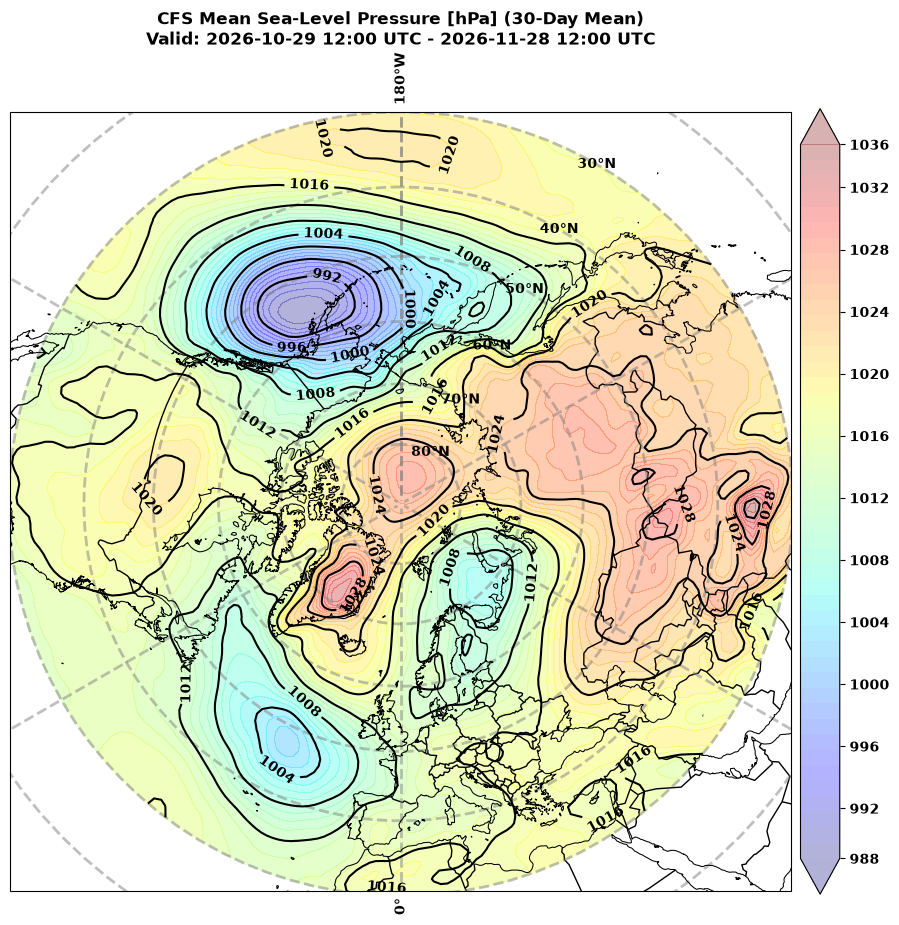

In [7]:
# Global setting for all text to be bold
plt.rcParams['font.weight'] = 'bold'

# Create our figure object
fig = plt.figure(figsize=(12,12))

# Create out axis and map coordinates reference system
ax = fig.add_subplot(1,1,1, projection=ccrs.NorthPolarStereo())

# Set our bounds and data coordinate reference system
ax.set_extent([-180, 180, 30, 90], ccrs.PlateCarree())

# Add coastlines for the outline of the coasts
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.75, zorder=9)

# Add our country borders
ax.add_feature(cfeature.BORDERS, linestyle='-', zorder=2)

init_time = pd.to_datetime(mean['time'].values)
final_time = init_time + timedelta(days=30)

# Create Our Title
ax.set_title(f"CFS Mean Sea-Level Pressure [hPa] (30-Day Mean)\nValid: {init_time.strftime('%Y-%m-%d %H:00 UTC')} - {final_time.strftime('%Y-%m-%d %H:00 UTC')}", 
             fontweight='bold',
             fontsize=12)

# Plot our gridlines
gl = ax.gridlines(draw_labels=True, linewidth=2, color='gray', alpha=0.5, linestyle='--')
gl.xlabels_top = False # Disable top labels
gl.ylabels_right = False # Disable right labels
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

# Create our increments for our filled and line contours
contour_levels = np.arange((np.nanmin(mean['mean_sea_level_pressure'])/100), ((np.nanmax(mean['mean_sea_level_pressure'])/100) + 4), 4)
filled_levels = np.arange((np.nanmin(mean['mean_sea_level_pressure'])/100), ((np.nanmax(mean['mean_sea_level_pressure'])/100) + 1), 1)
colorbar_ticks = np.arange(int(np.nanmin(mean['mean_sea_level_pressure'])/100), int((np.nanmax(mean['mean_sea_level_pressure'])/100) + 4), 4)

# Plot our contour data
c = ax.contour(longitude, 
            mean['latitude'], 
            mslp[:, :]/100, 
            transform=ccrs.PlateCarree(),
            zorder=2,
            colors='black',
            levels=contour_levels,
            alpha=1)

# Plot our filled contour data
cs = ax.contourf(longitude, 
            mean['latitude'], 
            mslp[:, :]/100, 
            cmap='jet', 
            transform=ccrs.PlateCarree(),
            levels=filled_levels,
            alpha=0.3,
            extend='both')

# Create our colorbar
fig.colorbar(cs, shrink=0.85, pad=0.01, ticks=colorbar_ticks)

# Label our contours
ax.clabel(c, inline=True, fontsize=10, fmt=lambda x: f"{int(x)}")